Setup

In [9]:
#importing necessary libraries
#may revisit this section if needed
#set up for modeling, confusion matrix, vis and eval
#had to first install tensorflow in anaconda

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns

1. Load the MNIST data set.

In [2]:
#loading the MNIST 'handwritten' digit dataset
#images are stored in x_train and x_test
#y_train and y_test correspond as labels


(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

11490434/11490434 [==============================] - 0s 0us/step


2. Display the first five images in the training data set. Compare these to the first five training labels.

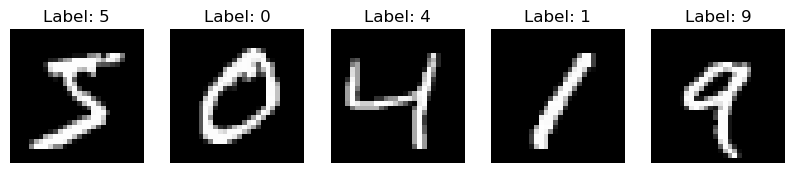

In [3]:
#showing first five images from train

fig, axes = plt.subplots(1, 5, figsize=(10, 2))

for i in range(5):
    axes[i].imshow(x_train[i], cmap='gray')
    axes[i].set_title(f"Label: {y_train[i]}")
    axes[i].axis('off')

#output
plt.show()

The training images are a success. The first five handwritten digits are legible and match their labels. This gives me confidence that the dataset loaded correctly and the image-label pairing is working as intended.

3. Build and train a CNN classifier on the MNIST training set.

In [4]:
#normalizing values from 0-255 to 0-1
#also reshaping the images

x_train = x_train / 255.0
x_test = x_test / 255.0

x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

This step is necessary for improving model performance. By reshaping them and scaling the values, the images can be processed by the CNN

In [5]:
#CNN
#using image features to learn
#reducing dimensionality

model = tf.keras.Sequential([
    tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

The CNN above uses two convolutional layers, two pooling layers and two dense layers, as seen in the code chunk.

In [6]:
#adam optimizer to compile
#five epochs of training using 10%

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train,
    y_train,
    epochs=5,
    validation_split=0.1
)

Epoch 1/5
1688/1688 [==============================] - 24s 14ms/step - loss: 0.1341 - accuracy: 0.9602 - val_loss: 0.0561 - val_accuracy: 0.9828
Epoch 2/5
1688/1688 [==============================] - 23s 13ms/step - loss: 0.0453 - accuracy: 0.9861 - val_loss: 0.0364 - val_accuracy: 0.9898
Epoch 3/5
1688/1688 [==============================] - 23s 14ms/step - loss: 0.0297 - accuracy: 0.9907 - val_loss: 0.0355 - val_accuracy: 0.9905
Epoch 4/5
1688/1688 [==============================] - 23s 14ms/step - loss: 0.0211 - accuracy: 0.9929 - val_loss: 0.0342 - val_accuracy: 0.9897
Epoch 5/5
1688/1688 [==============================] - 23s 13ms/step - loss: 0.0160 - accuracy: 0.9949 - val_loss: 0.0416 - val_accuracy: 0.9902


The output demonstrates the value of training for five epochs. Initially, epoch one starts at .96 accuracy. By epoch five, it's .9949, which is the highest accuracy of all the epochs. This suggests the model is learning the digit patterns

4. Report the test accuracy of your model.

In [7]:
#reporting accuracy

test_loss, test_acc = model.evaluate(x_test, y_test)

print("Test Accuracy:", test_acc)

313/313 [==============================] - 1s 4ms/step - loss: 0.0387 - accuracy: 0.9879
Test Accuracy: 0.9879000186920166


The final model performed very well with a test accuracy of 98.8%. This means the model is recognizing digit patterns and is also handling unseen data which is important for real-world usage

5. Display a confusion matrix on the test set classifications.

313/313 [==============================] - 1s 4ms/step


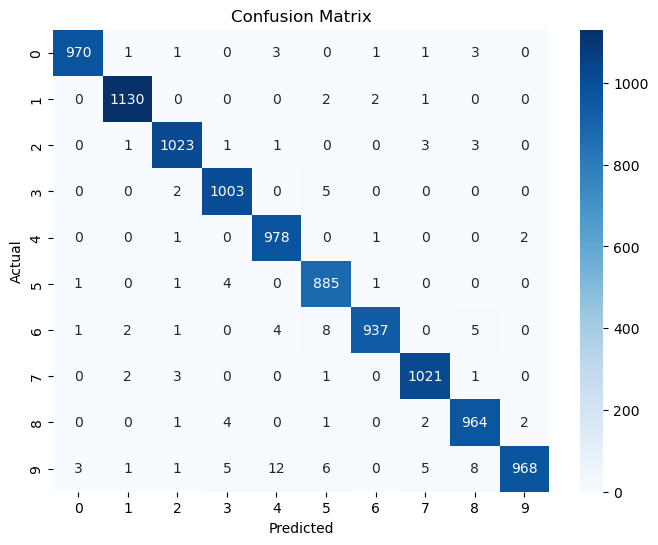

In [8]:
#confusion matrix for actual vs predicted

y_pred = np.argmax(model.predict(x_test), axis=1)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

The predictions are along the diagonal which is in line with the previously noted accuracy. While there are still some small errors, the model's overall performance is strong. This is nicely visualized by the confusion matrix.

6. Summarize your results.

Overall, the performance of the model is pretty successful. The goal was to see how effective a convolutional neural network would be at classifying handwritten digits from the dataset and it performed quite well. A final model accuracy of 98.8% is a great result and it was good to see the model improve from epoch one to epoch five. I think it's safe to say the CNN learned the image features well enough to give confidence in its classification abilities moving forward.